# Tyre degradation: training data and exploration

This notebook uses clean race laps and plots the estimated fuel-corrected lap time against tyre age. Fuel burn is corrected with an **illustrative estimate of 0.03 seconds per lap**; it is a parameter, not a measured physical constant. We keep rows with missing model fields in the loaded DataFrame, report them, and exclude only those rows from plots that need a compound and tyre age.

The clean-lap view currently exposes the event name rather than a separate circuit identifier. The loader calls that field `circuit` for analysis.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Find the project root even when Jupyter starts in notebooks/.
project_root = Path.cwd().resolve()
while not (project_root / "pyproject.toml").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not find the project root (pyproject.toml).")
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))
from f1engine.models import (
    DEFAULT_FUEL_BURN_SECONDS_PER_LAP,
    fit_linear_baselines,
    fit_naive_baseline,
    load_training_data,
)

FUEL_BURN_SECONDS_PER_LAP = DEFAULT_FUEL_BURN_SECONDS_PER_LAP
MIN_LAPS_TO_MODEL = 100
MIN_DRIVERS_TO_MODEL = 5
MIN_RACES_TO_MODEL = 2

print(
    "Fuel correction estimate:",
    FUEL_BURN_SECONDS_PER_LAP,
    "seconds per lap (illustrative, not measured)",
)

Fuel correction estimate: 0.03 seconds per lap (illustrative, not measured)


In [2]:
# Load every clean race lap. Missing compound or tyre-age values are not
# discarded here; the next cells show their counts before plotting.
training_data = load_training_data(
    estimated_fuel_burn_seconds_per_lap=FUEL_BURN_SECONDS_PER_LAP
)

print(f"Loaded {len(training_data):,} clean race laps")
print("Years:", sorted(training_data["year"].dropna().unique().tolist()))
print("Missing compounds:", int(training_data["compound"].isna().sum()))
print("Missing tyre ages:", int(training_data["tyre_life"].isna().sum()))
print(
    "Rows with missing compound or tyre age (excluded from these plots):",
    int((training_data["compound"].isna() | training_data["tyre_life"].isna()).sum()),
)

# Tyre age and compound are required only for this grouped EDA.
plot_data = training_data.dropna(
    subset=["circuit", "compound", "tyre_life", "fuel_corrected_lap_time_seconds"]
).copy()
plot_data["tyre_life"] = pd.to_numeric(plot_data["tyre_life"], errors="coerce")
plot_data = plot_data.dropna(subset=["tyre_life"])
print(f"Rows available for compound/age plots: {len(plot_data):,}")

Loaded 60,706 clean race laps
Years: [2022, 2023, 2024]
Missing compounds: 330
Missing tyre ages: 418
Rows with missing compound or tyre age (excluded from these plots): 479
Rows available for compound/age plots: 60,227


In [3]:
# A small-data flag is a conservative screening rule, not a statistical guarantee.
# Laps from the same driver/stint are related, so lap count alone is not enough.
# A race is identified by its year and round, not just its round number.
plot_data["race_id"] = (
    plot_data["year"].astype(str) + "-" + plot_data["round"].astype(str)
)
group_columns = ["circuit", "compound"]
combination_counts = (
    plot_data.groupby(group_columns, observed=True)
    .agg(
        lap_count=("lap_number", "size"),
        driver_count=("driver_code", "nunique"),
        race_count=("race_id", "nunique"),
    )
    .reset_index()
)
combination_counts["data_flag"] = "OK for initial modelling"
too_little_data = (
    (combination_counts["lap_count"] < MIN_LAPS_TO_MODEL)
    | (combination_counts["driver_count"] < MIN_DRIVERS_TO_MODEL)
    | (combination_counts["race_count"] < MIN_RACES_TO_MODEL)
)
combination_counts.loc[too_little_data, "data_flag"] = "TOO LITTLE DATA"
combination_counts = combination_counts.sort_values(
    ["data_flag", "circuit", "compound"]
)
print(
    "Screening rule: flag combinations with fewer than",
    MIN_LAPS_TO_MODEL,
    "laps or fewer than",
    MIN_DRIVERS_TO_MODEL,
    "drivers or fewer than",
    MIN_RACES_TO_MODEL,
    "separate races.",
)
with pd.option_context("display.max_rows", None):
    display(combination_counts.reset_index(drop=True))

Screening rule: flag combinations with fewer than 100 laps or fewer than 5 drivers or fewer than 2 separate races.


,circuit,compound,lap_count,driver_count,race_count,data_flag
0,Abu Dhabi Grand Prix,HARD,2026,26,3,OK for initial modelling
1,Abu Dhabi Grand Prix,MEDIUM,923,25,3,OK for initial modelling
2,Australian Grand Prix,HARD,1957,24,3,OK for initial modelling
3,Australian Grand Prix,MEDIUM,461,23,3,OK for initial modelling
4,Austrian Grand Prix,HARD,1882,24,3,OK for initial modelling
5,Austrian Grand Prix,MEDIUM,1409,24,3,OK for initial modelling
6,Azerbaijan Grand Prix,HARD,1946,26,3,OK for initial modelling
7,Azerbaijan Grand Prix,MEDIUM,533,25,3,OK for initial modelling
8,Bahrain Grand Prix,HARD,1335,21,3,OK for initial modelling
9,Bahrain Grand Prix,MEDIUM,302,20,2,OK for initial modelling


Circuits selected: ['Hungarian Grand Prix', 'Spanish Grand Prix', 'Mexico City Grand Prix']


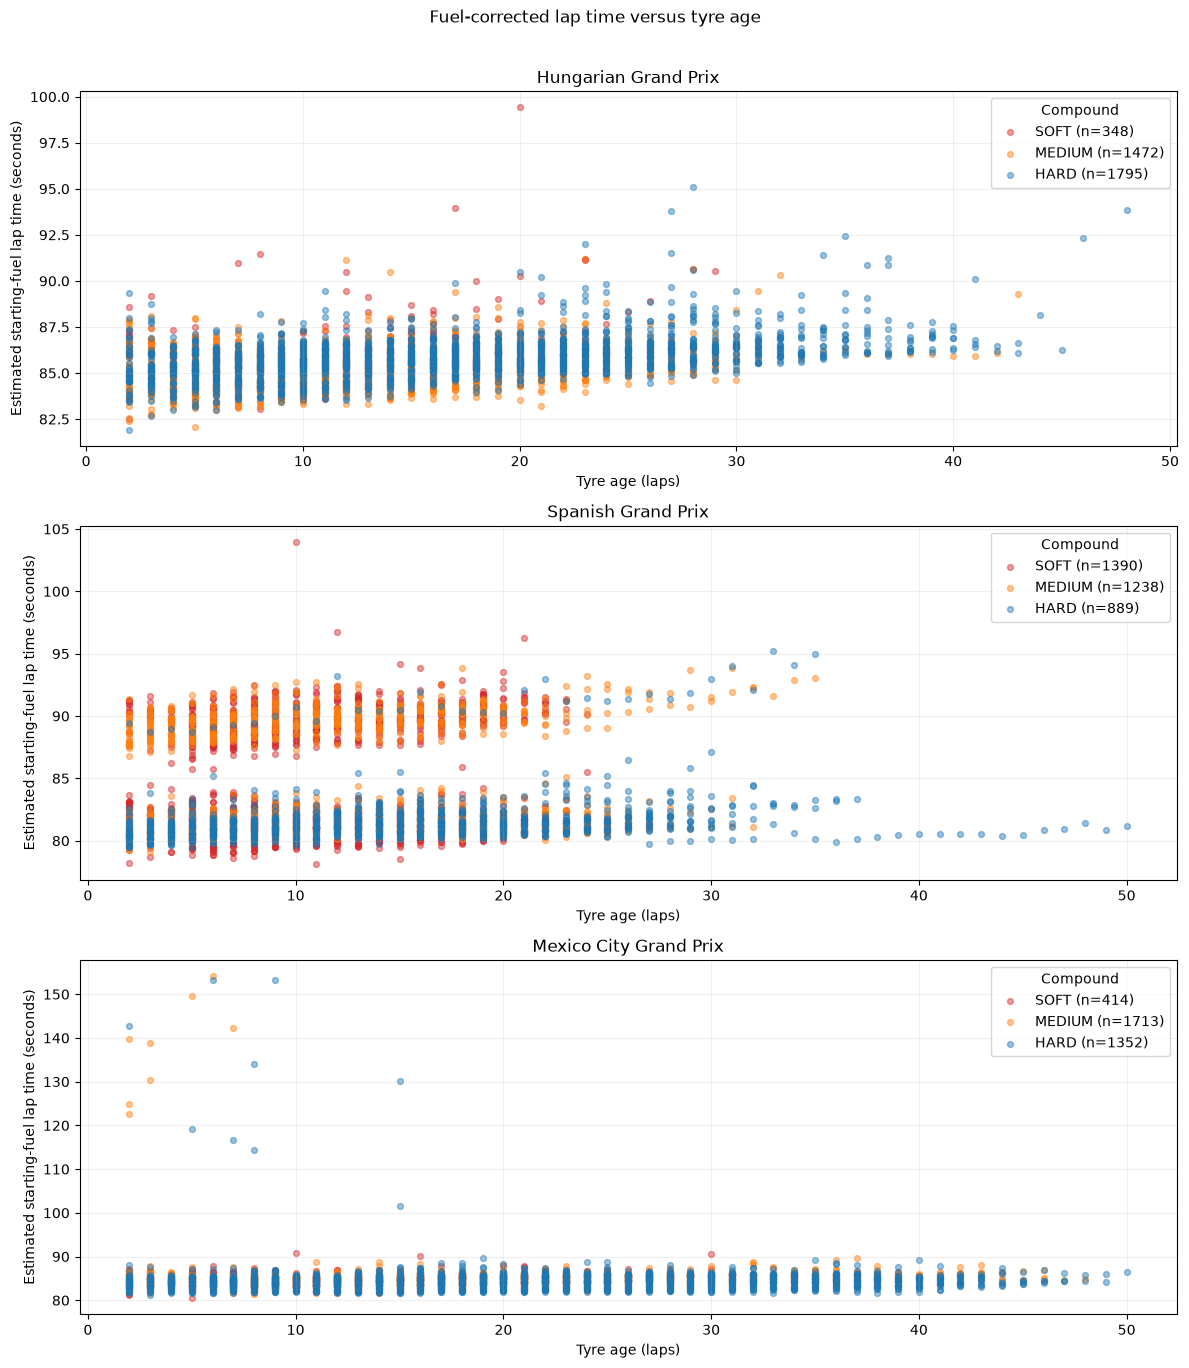

In [4]:
# Select three well-represented circuits that have all three dry compounds.
compound_coverage = plot_data.groupby("circuit")["compound"].nunique()
circuits_with_all_compounds = compound_coverage[compound_coverage >= 3].index
circuit_totals = (
    plot_data[plot_data["circuit"].isin(circuits_with_all_compounds)]
    .groupby("circuit")
    .size()
    .sort_values(ascending=False)
)
circuits_to_plot = circuit_totals.head(3).index.tolist()
if len(circuits_to_plot) < 2:
    raise ValueError(
        "Need at least two circuits with all three dry compounds to make these plots."
    )

print("Circuits selected:", circuits_to_plot)
fig, axes = plt.subplots(
    nrows=len(circuits_to_plot), ncols=1,
    figsize=(12, 4.5 * len(circuits_to_plot)),
    sharex=False,
)
if len(circuits_to_plot) == 1:
    axes = [axes]

compound_colors = {"SOFT": "tab:red", "MEDIUM": "tab:orange", "HARD": "tab:blue"}
for axis, circuit in zip(axes, circuits_to_plot):
    circuit_data = plot_data[plot_data["circuit"] == circuit]
    for compound in ("SOFT", "MEDIUM", "HARD"):
        compound_data = circuit_data[circuit_data["compound"] == compound]
        if compound_data.empty:
            continue
        axis.scatter(
            compound_data["tyre_life"],
            compound_data["fuel_corrected_lap_time_seconds"],
            label=f"{compound} (n={len(compound_data)})",
            color=compound_colors[compound],
            alpha=0.45,
            s=18,
        )
    axis.set_title(circuit)
    axis.set_xlabel("Tyre age (laps)")
    axis.set_ylabel("Estimated starting-fuel lap time (seconds)")
    axis.legend(title="Compound")
    axis.grid(alpha=0.2)

fig.suptitle("Fuel-corrected lap time versus tyre age", y=1.01)
fig.tight_layout()
plt.show()

## Baseline regression: adjust for driver pace

For each circuit/compound, the linear model estimates one common tyre-age slope while adding a separate fixed-effect offset for each driver. That way, a generally quicker driver does not automatically make their tyre-age trend look better. The slope is the estimated change in fuel-corrected lap time, in **seconds per additional tyre-life lap**. Positive means slower as the tyre ages; negative means faster in this sample. The R-squared is for the full model including driver terms, not just tyre age.

For a first-pass screen, only groups with at least 100 laps and five drivers are fitted. This is a practical threshold, not a proof of reliability. Small groups stay in the output with their row count and an explicit not-fitted status. A slope based on one race is descriptive of that race; repeated seasons let us compare whether estimates persist at the same circuit.

In [5]:
baseline_results, fixed_effect_models = fit_linear_baselines(
    plot_data,
    min_laps=MIN_LAPS_TO_MODEL,
    min_drivers=MIN_DRIVERS_TO_MODEL,
)

baseline_columns = [
    "circuit",
    "compound",
    "slope_seconds_per_lap",
    "number_of_laps",
    "r_squared",
    "number_of_drivers",
    "status",
]
with pd.option_context("display.max_rows", None):
    display(
        baseline_results[baseline_columns]
        .sort_values(["circuit", "compound"])
        .reset_index(drop=True)
    )

fitted_count = baseline_results["slope_seconds_per_lap"].notna().sum()
not_fitted_count = len(baseline_results) - fitted_count
print(
    f"Fitted {fitted_count} combinations; {not_fitted_count} were not fitted "
    "because they did not meet the minimum data rule."
)

,circuit,compound,slope_seconds_per_lap,number_of_laps,r_squared,number_of_drivers,status
0,Abu Dhabi Grand Prix,HARD,0.028907,2026,0.422568,26,Fitted
1,Abu Dhabi Grand Prix,MEDIUM,0.051814,923,0.455224,25,Fitted
2,Abu Dhabi Grand Prix,SOFT,NaN,67,NaN,4,Too little data
3,Australian Grand Prix,HARD,-0.019704,1957,0.187443,24,Fitted
4,Australian Grand Prix,MEDIUM,0.034729,461,0.386714,23,Fitted
5,Australian Grand Prix,SOFT,NaN,21,NaN,5,Too little data
6,Austrian Grand Prix,HARD,0.058405,1882,0.532444,24,Fitted
7,Austrian Grand Prix,MEDIUM,0.062329,1409,0.458636,24,Fitted
8,Austrian Grand Prix,SOFT,NaN,7,NaN,2,Too little data
9,Azerbaijan Grand Prix,HARD,-0.033208,1946,0.432814,26,Fitted


Fitted 60 combinations; 14 were not fitted because they did not meet the minimum data rule.


## Check slope stability between seasons

The pooled circuit/compound slopes above describe all stored years together. Here we also fit each season separately, then compare the slopes where at least two seasons have enough data. These are descriptive race-level estimates, so negative or unusually large values are reported rather than removed.

In [6]:
yearly_baseline_parts = []
for season_year, season_data in plot_data.groupby("year", sort=True):
    season_results, _ = fit_linear_baselines(
        season_data,
        min_laps=MIN_LAPS_TO_MODEL,
        min_drivers=MIN_DRIVERS_TO_MODEL,
    )
    season_results.insert(0, "year", int(season_year))
    yearly_baseline_parts.append(season_results)

yearly_baseline_results = pd.concat(yearly_baseline_parts, ignore_index=True)
measurable_slopes = yearly_baseline_results.dropna(
    subset=["slope_seconds_per_lap"]
)
slope_stability = (
    measurable_slopes.groupby(["circuit", "compound"], as_index=False)
    .agg(
        seasons_with_fit=("year", "nunique"),
        mean_slope_seconds_per_lap=("slope_seconds_per_lap", "mean"),
        slope_sd_between_seasons=("slope_seconds_per_lap", "std"),
        negative_season_slopes=("slope_seconds_per_lap", lambda values: int((values < 0).sum())),
        slopes_above_0_1=("slope_seconds_per_lap", lambda values: int((values > 0.1).sum())),
    )
    .query("seasons_with_fit >= 2")
    .sort_values(["circuit", "compound"])
)
print("Per-season estimates (including unusual slopes):")
display(
    measurable_slopes[
        ["year", "circuit", "compound", "slope_seconds_per_lap", "number_of_laps"]
    ].sort_values(["circuit", "compound", "year"])
)
print("Circuit/compound groups with fitted slopes in at least two seasons:")
display(slope_stability)
dry_compounds = measurable_slopes[
    measurable_slopes["compound"].isin(["SOFT", "MEDIUM", "HARD"])
]
compound_order = dry_compounds.pivot_table(
    index=["year", "circuit"],
    columns="compound",
    values="slope_seconds_per_lap",
).dropna(subset=["SOFT", "MEDIUM", "HARD"])
if compound_order.empty:
    print("No season/circuit has fitted slopes for all three dry compounds.")
else:
    compound_order["soft_gt_medium_gt_hard"] = (
        (compound_order["SOFT"] > compound_order["MEDIUM"])
        & (compound_order["MEDIUM"] > compound_order["HARD"])
    )
    print(
        "Expected SOFT > MEDIUM > HARD ordering in",
        int(compound_order["soft_gt_medium_gt_hard"].sum()),
        "of",
        len(compound_order),
        "complete season/circuit groups.",
    )
    display(compound_order)
print(
    "Fitted season slopes:", len(measurable_slopes),
    "| negative:", int((measurable_slopes["slope_seconds_per_lap"] < 0).sum()),
    "| above 0.1 sec/lap:",
    int((measurable_slopes["slope_seconds_per_lap"] > 0.1).sum()),
)

Per-season estimates (including unusual slopes):


,year,circuit,compound,slope_seconds_per_lap,number_of_laps
0,2022,Abu Dhabi Grand Prix,HARD,0.033256,580
57,2023,Abu Dhabi Grand Prix,HARD,0.029659,794
120,2024,Abu Dhabi Grand Prix,HARD,0.029642,652
1,2022,Abu Dhabi Grand Prix,MEDIUM,0.095516,409
58,2023,Abu Dhabi Grand Prix,MEDIUM,0.052453,269
...,...,...,...,...,...
117,2023,United States Grand Prix,HARD,0.035583,393
183,2024,United States Grand Prix,HARD,-0.008029,536
55,2022,United States Grand Prix,MEDIUM,0.016199,303
118,2023,United States Grand Prix,MEDIUM,0.020882,518


Circuit/compound groups with fitted slopes in at least two seasons:


,circuit,compound,seasons_with_fit,mean_slope_seconds_per_lap,slope_sd_between_seasons,negative_season_slopes,slopes_above_0_1
0,Abu Dhabi Grand Prix,HARD,3,0.030852,0.002081,0,0
1,Abu Dhabi Grand Prix,MEDIUM,3,0.066591,0.025051,0,0
2,Australian Grand Prix,HARD,3,-0.024280,0.051001,2,0
3,Australian Grand Prix,MEDIUM,2,0.026867,0.024755,0,0
4,Austrian Grand Prix,HARD,3,0.060116,0.006169,0,0
5,Austrian Grand Prix,MEDIUM,3,0.065454,0.017187,0,0
6,Azerbaijan Grand Prix,HARD,3,-0.019536,0.010138,3,0
7,Azerbaijan Grand Prix,MEDIUM,3,-0.002514,0.051359,2,0
8,Bahrain Grand Prix,HARD,2,0.060588,0.003985,0,0
10,Bahrain Grand Prix,SOFT,3,0.071610,0.015753,0,0


Expected SOFT > MEDIUM > HARD ordering in 3 of 9 complete season/circuit groups.


compound                         HARD    MEDIUM      SOFT  \
year circuit                                                
2022 British Grand Prix     -0.009866 -0.301277 -0.427217   
     Dutch Grand Prix        0.023015  0.039136  0.030842   
     Hungarian Grand Prix    0.040762  0.059780  0.184392   
     Italian Grand Prix      0.029697  0.005054  0.017270   
     Mexico City Grand Prix  0.038463  0.024525  0.042340   
2023 British Grand Prix     -0.008932 -0.011645 -0.005622   
     Spanish Grand Prix      0.022789  0.032230  0.023167   
2024 Dutch Grand Prix        0.029858  0.031688  0.047085   
     Spanish Grand Prix      0.051595  0.054694  0.055438   

compound                     soft_gt_medium_gt_hard  
year circuit                                         
2022 British Grand Prix                       False  
     Dutch Grand Prix                         False  
     Hungarian Grand Prix                      True  
     Italian Grand Prix                       False  
     Mexico City Grand Prix                   False  
2023 British Grand Prix                       False  
     Spanish Grand Prix                       False  
2024 Dutch Grand Prix                          True  
     Spanish Grand Prix                        True

Fitted season slopes: 137 | negative: 46 | above 0.1 sec/lap: 6


## Naive baseline for later model comparison

The naive predictor ignores tyre age and driver: it predicts the mean corrected lap time for each circuit/compound. This is a reference point, not a degradation model. When we later compare models with cross-validation, recompute these means using only each fold's training races; computing a mean once on the full data would leak held-out answers.

In [7]:
naive_baseline = fit_naive_baseline(plot_data)
display(naive_baseline.head(10))
print(
    "This table records the group means and training lap counts. "
    "For cross-validation, fit a fresh table inside each training fold."
)

,circuit,compound,naive_mean_lap_time_seconds,number_of_laps
0,Abu Dhabi Grand Prix,HARD,91.061550,2026
1,Abu Dhabi Grand Prix,MEDIUM,91.547683,923
2,Abu Dhabi Grand Prix,SOFT,91.888358,67
3,Australian Grand Prix,HARD,84.017646,1957
4,Australian Grand Prix,MEDIUM,84.810104,461
5,Australian Grand Prix,SOFT,83.689571,21
6,Austrian Grand Prix,HARD,72.145639,1882
7,Austrian Grand Prix,MEDIUM,71.732516,1409
8,Austrian Grand Prix,SOFT,70.485286,7
9,Azerbaijan Grand Prix,HARD,109.260161,1946


This table records the group means and training lap counts. For cross-validation, fit a fresh table inside each training fold.


## A few driver-adjusted linear fits

Dots are the observed laps. Each line shows the fitted trend for that combination's most frequently observed driver, holding the driver term fixed. It is an easy way to visualize the shared tyre-age slope without mixing in different driver offsets.

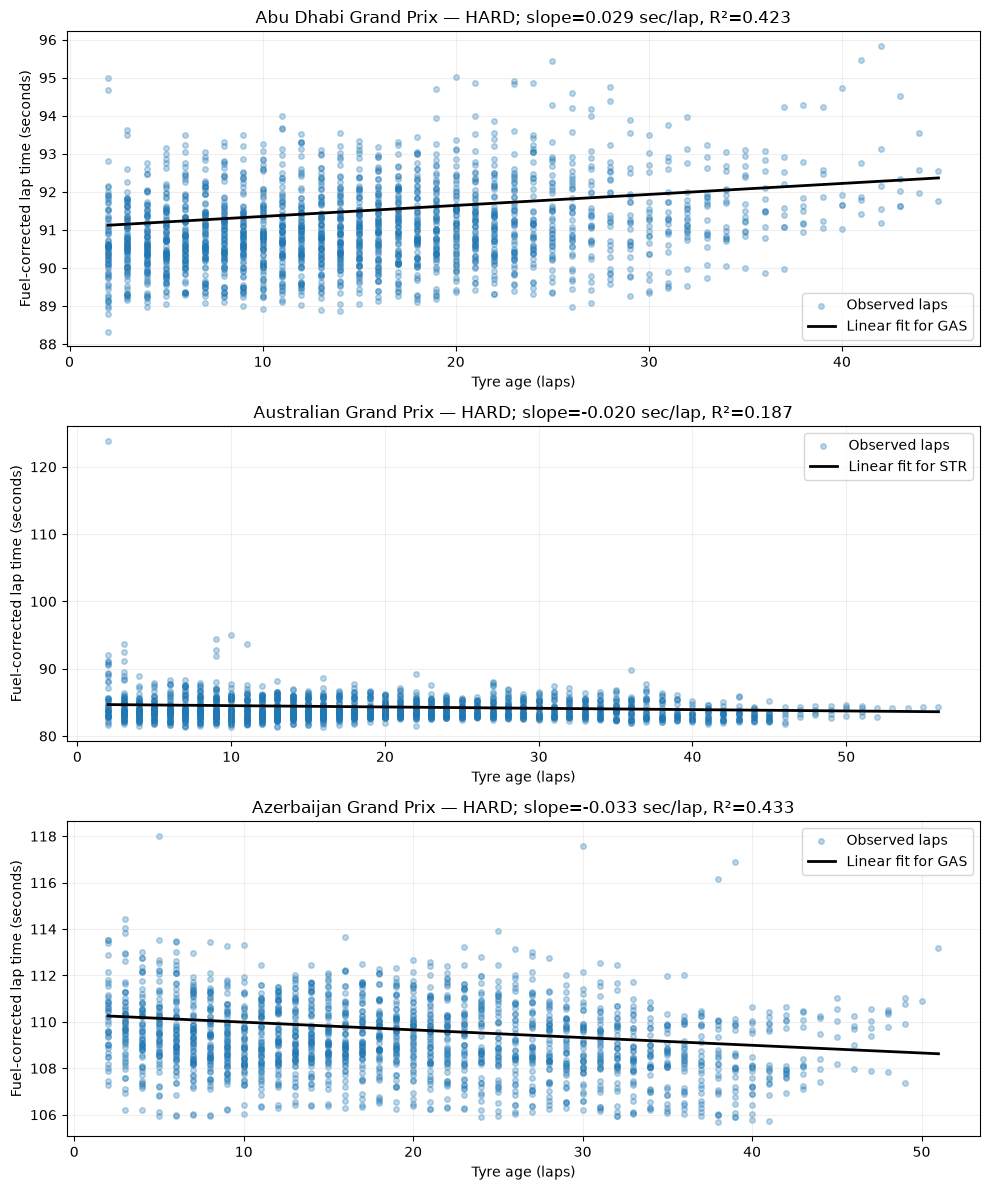

In [8]:
plot_fits = (
    baseline_results[baseline_results["slope_seconds_per_lap"].notna()]
    .sort_values("number_of_laps", ascending=False)
    .head(3)
)
if plot_fits.empty:
    print("No combinations met the minimum data rule, so there are no fits to plot.")
else:
    fig, axes = plt.subplots(
        nrows=len(plot_fits), ncols=1,
        figsize=(10, 4 * len(plot_fits)),
    )
    if len(plot_fits) == 1:
        axes = [axes]

    for axis, fit_row in zip(axes, plot_fits.itertuples(index=False)):
        key = (fit_row.circuit, fit_row.compound)
        model = fixed_effect_models[key]
        group_data = plot_data[
            (plot_data["circuit"] == fit_row.circuit)
            & (plot_data["compound"] == fit_row.compound)
        ]
        reference_driver = group_data["driver_code"].value_counts().idxmax()
        ages = pd.Series(
            range(int(group_data["tyre_life"].min()), int(group_data["tyre_life"].max()) + 1),
            name="tyre_life",
        )
        prediction_data = pd.DataFrame(
            {"tyre_life": ages, "driver_code": reference_driver}
        )

        axis.scatter(
            group_data["tyre_life"],
            group_data["fuel_corrected_lap_time_seconds"],
            alpha=0.3,
            s=16,
            label="Observed laps",
        )
        axis.plot(
            ages,
            model.predict(prediction_data),
            color="black",
            linewidth=2,
            label=f"Linear fit for {reference_driver}",
        )
        axis.set_title(
            f"{fit_row.circuit} — {fit_row.compound}; "
            f"slope={fit_row.slope_seconds_per_lap:.3f} sec/lap, "
            f"R²={fit_row.r_squared:.3f}"
        )
        axis.set_xlabel("Tyre age (laps)")
        axis.set_ylabel("Fuel-corrected lap time (seconds)")
        axis.legend()
        axis.grid(alpha=0.2)

    fig.tight_layout()
    plt.show()

## Race-held-out model evaluation

Every fold holds out one entire race using `LeaveOneGroupOut`; no random lap split is used. A random split would put laps from the same race, drivers, tyre stints, weather, and track evolution in both train and test, making performance look more general than it is.

With multiple seasons, some held-out circuits also appear in earlier training seasons while others are unseen. The Stage 2 per-circuit linear fits cannot be estimated for a held-out race at a never-before-seen circuit; for a usable comparator, this section uses a **pooled linear model with a separate tyre-age slope per compound and driver fixed effects**. The mixed model uses a compound-specific tyre-age slope and a random driver intercept. The boosted model uses compound, tyre age, lap number, circuit, team, and session-average track temperature when available.

The naive circuit/compound mean uses the training mean for the same circuit and compound when it is available; otherwise it falls back to the training-fold mean for that compound (or the overall training mean if that compound is absent). The fallback percentage is shown. Weather values are averaged over each race session because the stored weather table has timestamps but individual lap rows do not have a matching timestamp in `clean_laps`. Missing feature values are imputed using only the training fold.

In [9]:
from f1engine.models import evaluate_models_leave_one_race_out

cv_summary, cv_per_race = evaluate_models_leave_one_race_out(plot_data)
display(cv_summary)

best_model_name = cv_summary.iloc[0]["model"]
best_model_race_errors = (
    cv_per_race[cv_per_race["model"] == best_model_name]
    .sort_values(["mae_seconds", "year", "round"])
    .reset_index(drop=True)
)
print(f"Best by mean per-race MAE: {best_model_name}")
display(
    best_model_race_errors[
        ["year", "round", "circuit", "mae_seconds", "number_of_laps"]
    ]
)

naive_result = cv_summary[
    cv_summary["model"] == "Naive circuit/compound mean"
].iloc[0]
best_result = cv_summary.iloc[0]
if best_model_name == "Naive circuit/compound mean":
    print("The naive baseline is the best model under this race-held-out metric.")
else:
    improvement = (
        naive_result["mean_race_mae_seconds"]
        - best_result["mean_race_mae_seconds"]
    )
    print(
        f"Best model lowers mean race MAE by {improvement:.3f} seconds "
        "versus the naive baseline. Treat this as a 2024 unseen-circuit "
        "comparison, not proof of future-season performance."
    )

mixed_cv = cv_summary[
    cv_summary["model"] == "Driver random-intercept MixedLM"
].iloc[0]
print(
    "MixedLM converged in",
    int(mixed_cv["mixedlm_converged_folds"]),
    "of",
    int(mixed_cv["number_of_races"]),
    "folds; non-zero driver effects were used in",
    int(mixed_cv["mixedlm_driver_effect_folds"]),
    "folds.",
)

,model,mean_race_mae_seconds,standard_deviation_race_mae_seconds,number_of_races,rank,naive_group_fallback_pct,mixedlm_converged_folds,mixedlm_driver_effect_folds
0,Naive circuit/compound mean,2.283070,2.550846,66,1,3.056117,NaN,NaN
1,HistGradientBoostingRegressor,2.989151,2.980710,66,2,NaN,NaN,NaN
2,Driver random-intercept MixedLM,9.334432,5.917129,66,3,NaN,66.0,66.0
3,Pooled driver-fixed-effects linear,9.335910,5.909792,66,4,NaN,NaN,NaN


Best by mean per-race MAE: Naive circuit/compound mean


,year,round,circuit,mae_seconds,number_of_laps
0,2023,22,Abu Dhabi Grand Prix,0.667000,1063
1,2022,11,Austrian Grand Prix,0.679457,843
2,2023,11,Hungarian Grand Prix,0.692725,1158
3,2024,11,Austrian Grand Prix,0.700528,1269
4,2023,9,Austrian Grand Prix,0.768848,1186
...,...,...,...,...,...
61,2024,14,Belgian Grand Prix,5.062551,751
62,2022,6,Spanish Grand Prix,8.472844,1104
63,2022,12,French Grand Prix,10.408134,833
64,2024,5,Chinese Grand Prix,12.417120,762


The naive baseline is the best model under this race-held-out metric.
MixedLM converged in 66 of 66 folds; non-zero driver effects were used in 66 folds.


## Chronological held-out-season evaluation

This stricter check predicts each season using only earlier seasons. The earliest season is training-only. It answers a different question from race-held-out CV: how well the fitted patterns carry forward to a future season, including year-to-year changes in teams and pace.

In [10]:
from f1engine.models import evaluate_models_held_out_seasons

season_cv_summary, season_cv_by_year = evaluate_models_held_out_seasons(plot_data)
display(season_cv_summary)
display(season_cv_by_year)

,model,mean_season_mae_seconds,number_of_seasons,rank
0,Naive circuit/compound mean,2.601909,2,1
1,HistGradientBoostingRegressor,3.254669,2,2
2,Driver random-intercept MixedLM,8.873214,2,3
3,Pooled driver-fixed-effects linear,8.909926,2,4


,held_out_year,model,mae_seconds,number_of_laps,naive_group_fallback_pct,mixedlm_converged,mixedlm_used_driver_effects
0,2023,Driver random-intercept MixedLM,9.001529,20626,NaN,True,True
1,2023,HistGradientBoostingRegressor,3.890213,20626,NaN,None,None
2,2023,Naive circuit/compound mean,2.928959,20626,13.769029,None,None
3,2023,Pooled driver-fixed-effects linear,9.077711,20626,NaN,None,None
4,2024,Driver random-intercept MixedLM,8.744899,21727,NaN,True,True
5,2024,HistGradientBoostingRegressor,2.619125,21727,NaN,None,None
6,2024,Naive circuit/compound mean,2.274860,21727,3.507157,None,None
7,2024,Pooled driver-fixed-effects linear,8.742142,21727,NaN,None,None


## Save an exploratory degradation fit and try predictions

In the expanded data, the naive circuit/compound mean wins both race-held-out and chronological season-held-out evaluation. The MixedLM is therefore **not** the winning lap-time predictor. We still refit it on all 2022–2024 rows with complete modeling fields as an exploratory, interpretable wear fit and save it with joblib. Its predicted loss relative to tyre age one subtracts the circuit intercept; the fit uses pooled compound slopes rather than circuit-specific wear rates. The output below includes physical sanity checks, and negative predicted losses are a warning not to use this artifact for race strategy.

`cliff_lap` has a deliberately modest definition: the first age when the model predicts a lap at least one second slower than a fresh age-one tyre, and only if that age is within the observed age range for the compound. It returns `None` when the threshold is not reached in observed data. This straight-line model cannot detect a sudden physical cliff.

In [11]:
from f1engine.models import (
    DEFAULT_DEGRADATION_MODEL_PATH,
    cliff_lap,
    predict_degradation,
    save_degradation_model,
)

saved_model_path = save_degradation_model(training_data=plot_data)
print(f"Saved exploratory v3 stint-slope fit: {saved_model_path}")
print(f"Artifact size: {saved_model_path.stat().st_size:,} bytes")

prediction_examples = [
    ("Bahrain Grand Prix", "SOFT", 20),
    ("Italian Grand Prix", "MEDIUM", 20),
    ("Dutch Grand Prix", "HARD", 20),
]
prediction_rows = []
for circuit, compound, age in prediction_examples:
    predicted_loss, lower, upper, reliable = predict_degradation(
        circuit, compound, age
    )
    observed_fit = baseline_results[
        (baseline_results["circuit"] == circuit)
        & (baseline_results["compound"] == compound)
    ].iloc[0]
    prediction_rows.append(
        {
            "circuit": circuit,
            "compound": compound,
            "tyre_age": age,
            "predicted_loss_vs_age_1_seconds": predicted_loss,
            "lower_95_seconds": lower,
            "upper_95_seconds": upper,
            "reliable": reliable,
            "pooled_model_slope_seconds_per_lap": predicted_loss / (age - 1),
            "combined_fit_slope_seconds_per_lap": observed_fit[
                "slope_seconds_per_lap"
            ],
            "planning_threshold_lap": cliff_lap(
                circuit, compound
            ),
        }
    )
prediction_table = pd.DataFrame(prediction_rows)
display(prediction_table)
print("Use the reliability flag and interval; the cliff helper is only a planning threshold.")

Saved exploratory MixedLM fit: C:\Users\Taksh Doshi\OneDrive\Desktop\f1-telemetry-engine\models\tyre_degradation_mixedlm.joblib
Artifact size: 3,156,994 bytes


,circuit,compound,tyre_age,predicted_loss_vs_age_1_seconds,pooled_model_slope_seconds_per_lap,combined_fit_slope_seconds_per_lap,one_second_cliff_lap_within_observed_range
0,Bahrain Grand Prix,SOFT,20,-0.379192,-0.019957,0.074519,None
1,Italian Grand Prix,MEDIUM,20,-0.135581,-0.007136,0.050307,None
2,Dutch Grand Prix,HARD,20,0.074865,0.003940,0.020609,None


The cliff helper returns None when no observed tyre age reaches the 1-second loss threshold.


## Reading these plots

Look for a rising cloud as tyre age increases, but do not interpret every upward pattern as tyre wear. Fuel correction is only an estimate; traffic, track evolution, safety-car periods, driver pace, and which tyres survive to later laps can all change the shape. A long tail with few points is especially uncertain. The table flags combinations with fewer than 100 laps, fewer than five drivers, or fewer than two races. Even a high lap count from one race is not independent evidence that the slope generalizes to other races.